# RDD Examples — PySpark

**Contents**

**Part 1 — Getting started**
1. Setup & key terms
2. Sample data files
3. Creating RDDs — from collections and local files
4. Transformations & actions on numbers
5. Caching / persisting

**Part 2 — Narrow transformations (no shuffle)**

6. Working with text files
7. `map` vs `flatMap`
8. `filter`
9. `keyBy`

**Part 3 — Wide transformations (shuffle)**

10. Narrow vs wide transformations
11. `groupBy`
12. `groupByKey`
13. `reduceByKey` — average per key
14. `join`
15. `distinct`

**Part 4 — Actions**

16. More actions: `reduce`, `max`, `min`, `mean`, `variance`, `stdev`
17. `countByKey`

**Part 5 — Storage, limits & wrap-up**

18. Working with **Hadoop HDFS** (read & write)
19. RDDs have no schema — the "bad data" example
20. RDD vs DataFrame
21. Stages & stopping Spark
22. 📋 Cheat sheet — summary of everything

> 💡 Comments starting with `# ->` show the expected output.

## 1. Setup & key terms

| Term | Meaning |
|---|---|
| **Application** | A user program built on Spark: one driver program + executors on the cluster |
| **SparkSession** | The entry point to Spark. In the `pyspark` shell it already exists; in your own program you create it |
| **RDD** | Resilient Distributed Dataset |
| **Transformation** | An operation that produces a **new RDD** (lazy — nothing runs yet) |
| **Action** | An operation that returns a **local result** to the driver (triggers the work) |
| **Job** | The parallel computation started by an action (e.g. `collect()`, `save()`) |
| **Stage** | A job is split into stages that depend on each other |
| **Task** | A single unit of work sent to one executor |

### 1.1 Creating the SparkContext
The older way (Spark 1.x) — create the `SparkContext` yourself from a `SparkConf`.
Only **one** SparkContext can exist per JVM, so don't run this if `sc` already exists:

In [ ]:
from pyspark import SparkConf, SparkContext

sconf = SparkConf().setMaster('local[*]').setAppName('RDD')

sc = SparkContext(conf=sconf)

print(sc.master)                 # -> yarn
sc

### 1.2 Creating a SparkSession (the modern way)
No `.master(...)` is set here, so Spark uses the cluster's default from `spark-defaults.conf`.
On the Docker cluster that is **`yarn`**: the driver runs in this notebook, and the executors run on worker1–worker4.
To run everything on this one machine instead, add `.master('local[*]')` to the builder.

In [ ]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName('RDD').getOrCreate()
sc = spark.sparkContext          # the SparkContext lives inside the SparkSession

print(sc.master)                 # -> yarn
sc

In [ ]:
from pyspark.sql import SparkSession

spark = (SparkSession.builder.appName('RDD').master('local[*]').getOrCreate()) # run locally, one thread per CPU core

sc = spark.sparkContext
print(sc.master)                 # -> local[*]
sc

### 1.3 Local mode vs YARN

| | Local mode (`local[*]`) | YARN (`yarn`) |
|---|---|---|
| **Where the work runs** | Inside worker4 only, if the notebook runs there | Executors run on available YARN worker nodes, potentially worker1–worker4 |
| **Driver and executors** | The driver and local execution run in the same JVM process | In YARN client mode, the driver runs with your notebook; executors run in separate YARN containers |
| **Start-up time** | Fast, typically a few seconds | Usually slower because YARN must allocate and start containers |
| **Shows in YARN UI (`localhost:18088`)** | No | Yes, if the ResourceManager UI is accessible at that address |
| **Good for** | Learning, testing, and small data | Large datasets and parallel work across machines |

**Note:** `local[*]` uses all available logical cores on the machine running the Spark driver. The YARN driver location depends on deploy mode: the table describes client mode; in cluster mode, the driver also runs in a YARN container.

## 2. Sample data files
All the files used here are in the `data/` folder next to this notebook:

| Folder | Files | What's inside |
|---|---|---|
| `data/csv/` | `2010-summary.csv` … `2015-summary.csv` | Flights per route: `DEST_COUNTRY_NAME,ORIGIN_COUNTRY_NAME,count` — 6 files, 1531 lines (headers included) |
| `data/json/` | `2010-summary.json` … `2015-summary.json` | The same flights, one JSON object per line — 1525 lines |
| `data/text/` | `example.txt`, `example2.txt`, `text.txt` | Short text files for `map` / `flatMap` / `filter` |

The flight files follow the format of the course dataset (the original notebooks read it from
`/home/el-neshwy/Documents/DataFrameworks/DataFiles/`). The numbers are sample values, so counts differ
from the ones seen in class.

**On the cluster** the same `data/` folder is also uploaded to HDFS at `/user/user/data`.
A relative path like `data/csv` given to Spark means *your HDFS home folder* (`/user/user/data/csv`),
while Python's own `os.listdir` / `open` below read the local copy next to the notebook. See section 18.

In [ ]:
import os

DATA_DIR = 'data'
CSV_DIR  = f'{DATA_DIR}/csv'
JSON_DIR = f'{DATA_DIR}/json'
TEXT_DIR = f'{DATA_DIR}/text'

for d in (CSV_DIR, JSON_DIR, TEXT_DIR):
    print(d, '->', sorted(os.listdir(d)))

In [ ]:
for name in ('example.txt', 'example2.txt', 'text.txt'):
    print(f'--- {name} ---')
    print(open(f'{TEXT_DIR}/{name}').read())

## 3. Creating RDDs
There are two ways to create an RDD:

| Method | Result |
|---|---|
| `sc.parallelize(array)` | RDD from the elements of a list / array in the driver |
| `sc.textFile(path)` | RDD of **lines** from a file (or every file in a folder) |

Spark can read from any Hadoop-supported storage: local files, HDFS, Cassandra, HBase, Amazon S3, …

> Reading from and writing to **HDFS** is covered later, in section 18, after `map` and `filter` are explained.

### 3.1 From a collection — `parallelize`

In [ ]:
import math     # plain Python math (numpy isn't installed on the cluster's workers)

data = list(range(1, 51))
data[:10]
# -> [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

In [ ]:
rdd1 = sc.parallelize(data)
rdd1
# -> ParallelCollectionRDD[0] at readRDDFromFile ...

In [ ]:
rdd1.getNumPartitions()
# -> depends on the cores available (20 on the instructor's laptop with local[*])

### 3.2 From files — `textFile`

In [ ]:
distFile = sc.textFile(f'{TEXT_DIR}/example.txt')    # one file
distFile
# -> data/text/example.txt MapPartitionsRDD[...] at textFile ...

In [ ]:
distFile2 = sc.textFile(CSV_DIR)              # a whole folder: every file in it
distFile2

In [ ]:
print(distFile.getNumPartitions())    # -> 2
print(distFile2.getNumPartitions())   # -> 6 (one per file — these files are small)

In [ ]:
# Ask Spark for at least 8 partitions
distFile2_P = sc.textFile(CSV_DIR, minPartitions=8)
distFile2_P.getNumPartitions()

In [ ]:
print(distFile.count())     # -> 4  (4 lines)
print(distFile2.count())    # -> 1531  (all lines of the 6 CSV files — the 6 headers included!)

In [ ]:
distFile.collect()
# -> ['first line', 'second line', 'third line', 'fourth line']

In [ ]:
# collect() would bring back all 1531 lines — take() shows just a few
distFile2.take(5)
# -> ['DEST_COUNTRY_NAME,ORIGIN_COUNTRY_NAME,count', '...,United States,...', ...]

In [ ]:
distFile3 = sc.textFile(JSON_DIR)    # JSON files are also read line by line, as plain strings
print(distFile3.count())             # -> 1525  (no header line in JSON)
distFile3.take(3)
# -> ['{"ORIGIN_COUNTRY_NAME":"United States","DEST_COUNTRY_NAME":"...","count":...}', ...]

> ⚠️ `textFile` only understands **text**. In class, reading a Parquet file with
> `sc.textFile('.../2010-summary.parquet')` returned unreadable binary characters.
> Use `spark.read.parquet(...)` (DataFrames) for Parquet.

## 4. Transformations & actions on numbers
Transformations are **lazy**: `map` only records the step and returns a new RDD.
Nothing is computed until an **action** like `collect()`, `count()` or `sum()` runs.

In [ ]:
rdd1.collect()

In [ ]:
rdd2 = rdd1.map(lambda x: x**2)     # transformation -> new RDD, nothing runs yet
rdd2
# -> PythonRDD[1] at RDD at PythonRDD.scala:53

You can pass a normal Python function instead of a lambda:

In [ ]:
def f(x):
    return math.sqrt(x)

rdd3 = rdd2.map(f)
rdd3.getNumPartitions()     # same number of partitions as rdd1

In [ ]:
print(rdd1.collect()[:5])   # -> [1, 2, 3, 4, 5]
print(rdd2.collect()[:5])   # -> [1, 4, 9, 16, 25]
print(rdd3.collect()[:5])   # -> [1.0, 2.0, 3.0, 4.0, 5.0]

In [ ]:
rdd4 = rdd3.map(lambda x: x + 2)
rdd5 = rdd4.map(lambda x: x / 3)
rdd6 = rdd4.map(lambda x: x + x)

print(rdd4.collect()[:3])   # -> [3.0, 4.0, 5.0]
print(rdd5.collect()[:3])   # -> [1.0, 1.3333333333333333, 1.6666666666666667]
print(rdd6.collect()[:3])   # -> [6.0, 8.0, 10.0]

### Simple actions

In [ ]:
print(rdd1.take(5))     # -> [1, 2, 3, 4, 5]   first 5 elements
print(rdd1.first())     # -> 1
print(rdd5.count())     # -> 50
print(rdd2.sum())       # -> 42925

In [ ]:
rdd5.reduce(lambda a, b: a + b)
# -> 458.3333333333333

Transformations can be **chained** — Spark runs the whole chain only when the action (`reduce`) is called:

In [ ]:
rdd1.map(lambda x: x**2).map(lambda x: x + x).map(f).reduce(lambda a, b: a + b)
# -> 1803.1222920256964

In [ ]:
# From Day 1
r2 = rdd1.map(lambda x: x**2)
r3 = rdd1.map(lambda x: math.sqrt(x))
r4 = rdd1.map(lambda x: x**3)
r5 = r2.map(lambda x: x + 5)

print(r2.sum())        # -> 42925
print(r4.count())      # -> 50
print(r5.take(5))      # -> [6, 9, 14, 21, 30]
print(r3.stdev())      # -> 1.626270091938464
print(r3.mean())       # -> 4.780716012070417

## 5. Caching / persisting
`cache()` keeps an RDD in memory after the **first action** computes it, so later actions reuse it
instead of recomputing the whole chain. `cache()` itself is lazy.

- `rdd.cache()` → storage level `MEMORY_ONLY` for RDDs
- `rdd.persist(StorageLevel.MEMORY_AND_DISK)` → partitions that don't fit in memory go to local disk
- `rdd.unpersist()` → remove it from the cache

In [ ]:
from pyspark import StorageLevel

rdd3.cache()

In [ ]:
rdd3.count()            # first action: computes rdd3 and stores it in memory

In [ ]:
rdd3.sum()              # reuses the cached data

| Position | Meaning | Our value |
|----------|---------|-----------|
| 1 | Use **disk**? | `True` ✅ |
| 2 | Use **memory**? | `True` ✅ |
| 3 | Use off-heap memory? (advanced) | `False` |
| 4 | Store data in deserialized form? | `False` |
| 5 | How many **copies**? | `1` |

| Storage level | Where data is stored | What happens |
|---------------|----------------------|--------------|
| `MEMORY_ONLY` | RAM only ⚡ | Partitions that don’t fit **aren’t saved** and are recomputed when needed. |
| `MEMORY_AND_DISK` | RAM first, then disk 💾 | Partitions that don’t fit in memory **are stored on disk**. |
| `DISK_ONLY` | Disk only 🗄️ | Partitions are stored on disk. |

In [ ]:
rdd1.unpersist()
rdd1.persist(StorageLevel.MEMORY_AND_DISK)
rdd1.getStorageLevel()

## 6. Working with text files

In [ ]:
text_rdd = sc.textFile(f'{TEXT_DIR}/example2.txt')
text_rdd.take(2)
# -> ['first ', 'second line']

### `collect()`
Action — returns **all** items of the RDD to the driver as one Python list.
Use it only on small results.

![](http://i.imgur.com/DUO6ygB.png)

In [ ]:
text_rdd.collect()
# -> ['first ', 'second line', 'the third line', 'then a fourth line']

In [ ]:
distFile.first()
# -> 'first line'

In [ ]:
lst = distFile.collect()     # a normal Python list now
lst[0]
# -> 'first line'

Length of every line, then add them up:

In [ ]:
distFile_mapped = distFile.map(lambda s: len(s))
print(distFile_mapped.collect())                     # -> [10, 11, 10, 11]
print(distFile_mapped.reduce(lambda a, b: a + b))    # -> 42

### Splitting CSV lines

In [ ]:
def s(x):
    return x.split()

s('ahmed mohamed hany')
# -> ['ahmed', 'mohamed', 'hany']

In [ ]:
# split() cuts on spaces -> wrong for CSV
distFile2_mapped = distFile2.map(s)
distFile2_mapped.take(3)
# -> [['DEST_COUNTRY_NAME,ORIGIN_COUNTRY_NAME,count'], ['United', 'States,Romania,1'], ...]

In [ ]:
# split(',') cuts on commas -> one list per row
distFile2_mapped_Comma = distFile2.map(lambda s: s.split(','))
distFile2_mapped_Comma.take(3)
# -> [['DEST_COUNTRY_NAME', 'ORIGIN_COUNTRY_NAME', 'count'], ['United States', 'Romania', '1'], ...]

## 7. `map` vs `flatMap`

### `map`
Transformation / **narrow** — apply a function to **each** element. One input → exactly one output.

![](http://i.imgur.com/PxNJf0U.png)

In [ ]:
rdd = sc.parallelize(list(range(8)))
print('rdd elements:         ', rdd.collect())
print('rdd elements squared: ', rdd.map(lambda x: x ** 2).collect())
# -> rdd elements:          [0, 1, 2, 3, 4, 5, 6, 7]
# -> rdd elements squared:  [0, 1, 4, 9, 16, 25, 36, 49]

In [ ]:
def sq(no):
    return no**2

rdd.map(sq).collect()
# -> [0, 1, 4, 9, 16, 25, 36, 49]

In [ ]:
textRddlst = text_rdd.map(lambda line: line.split()).collect()
textRddlst
# -> [['first'], ['second', 'line'], ['the', 'third', 'line'], ['then', 'a', 'fourth', 'line']]

In [ ]:
print(textRddlst[1])       # -> ['second', 'line']
print(textRddlst[1][0])    # -> 'second'

### `flatMap`
Transformation / **narrow** — apply the function, then **flatten** the results into one list.
One input → zero, one or many outputs.

![](http://i.imgur.com/TsSUex8.png)

In [ ]:
lstFlatMap = text_rdd.flatMap(lambda line: line.split()).collect()
lstFlatMap
# -> ['first', 'second', 'line', 'the', 'third', 'line', 'then', 'a', 'fourth', 'line']

In [ ]:
lstFlatMap[8]
# -> 'fourth'

Same idea with `text.txt`:

In [ ]:
rddtxt = sc.textFile(f'{TEXT_DIR}/text.txt')
rddtxt.cache()

rddmap = rddtxt.map(lambda x: x.split())
rddflatmap = rddtxt.flatMap(lambda x: x.split())

print(rddmap.collect())
# -> [['cat', 'dog', 'cat'], ['snake', 'cat', 'dog'], ['snake', 'dog', 'owl'], ['owl', 'snake', 'cat']]
print(rddflatmap.collect())
# -> ['cat', 'dog', 'cat', 'snake', 'cat', 'dog', 'snake', 'dog', 'owl', 'owl', 'snake', 'cat']

## 8. `filter`
Transformation / **narrow** — keep only the elements where the function returns `True`.

![](http://i.imgur.com/GFyji4U.png)

In [ ]:
rdd = sc.parallelize(list(range(8)))
rdd.filter(lambda x: x % 2 == 0).collect()
# -> [0, 2, 4, 6]

In [ ]:
secfind = distFile.filter(lambda line: 'second' in line)
thrdfind = distFile.filter(lambda line: 'third' in line)
print(secfind.collect())     # -> ['second line']
print(thrdfind.collect())    # -> ['third line']

In [ ]:
# Every line that mentions Egypt (as destination OR origin)
EGYfind = distFile2.filter(lambda line: 'Egypt' in line)
print(EGYfind.collect())
print(EGYfind.count())     # -> 12  (to Egypt + from Egypt, one of each per year)

In [ ]:
# Remove the header lines
rdd_filter = distFile2.filter(lambda x: 'DEST_COUNTRY_NAME' not in x)
rdd_filter.take(5)

In [ ]:
# Filter on a column after splitting: destination == Egypt only
rdd_egy = distFile2_mapped_Comma.filter(lambda x: x[0] == 'Egypt')
print(rdd_egy.take(5))     # -> [['Egypt', 'United States', '...'], ...]
print(rdd_egy.count())     # -> 6

## 9. `keyBy`
Transformation / **narrow** — turn each element into a pair `(key, element)`. The key is computed by your function.
The result is a **pair RDD** that works with the `...ByKey` operations.

![](http://i.imgur.com/nqYhDW5.png)

In [ ]:
rdd = sc.parallelize(['John', 'Fred', 'Anna', 'James'])
rdd.keyBy(lambda w: w[0]).collect()
# -> [('J', 'John'), ('F', 'Fred'), ('A', 'Anna'), ('J', 'James')]

In [ ]:
rddkeys = rddflatmap.keyBy(lambda x: x[0])
rddkeys.collect()
# -> [('c', 'cat'), ('d', 'dog'), ('c', 'cat'), ('s', 'snake'), ...]

In [ ]:
distFile2_mapped_Comma_Keys = distFile2_mapped_Comma.keyBy(lambda x: x[0])               # key = destination
distFile2_mapped_Comma_Keys_2 = distFile2_mapped_Comma.keyBy(lambda x: (x[0], x[1]))     # key = (destination, origin)

print(distFile2_mapped_Comma_Keys.take(3))
print(distFile2_mapped_Comma_Keys_2.take(3))

# keyBy is narrow: the number of elements doesn't change
print(distFile2_mapped_Comma_Keys.count(), distFile2_mapped_Comma_Keys_2.count())    # -> 1531 1531

## 10. Narrow vs wide transformations
RDDs are **immutable** — you never change one; you describe *how* to build a new one. Those instructions are
transformations, and there are two kinds.

<b>Narrow transformation — specify narrow dependencies</b>
Narrow transformation are those where each input partition will contribute to only one output partition.
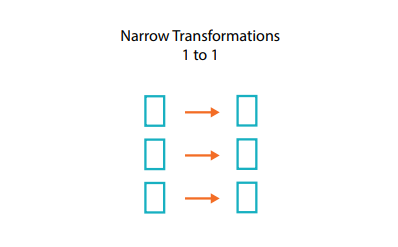
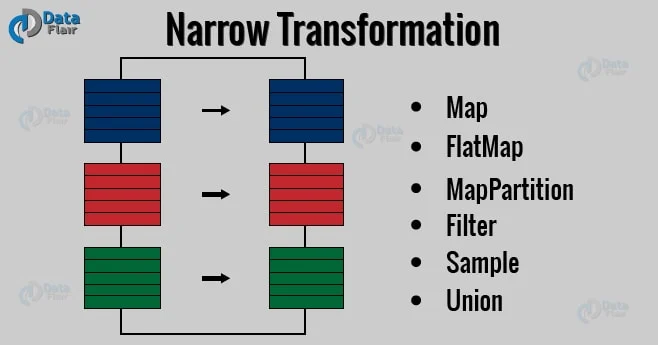

<b>Wide transformation — specify wide dependencies.</b>
Wide transformation will have input partitions contributing to many output partitions.
You will often hear this referred to as a <i><b>shuffle</b></i> where Spark will exchange partitions across the cluster. 
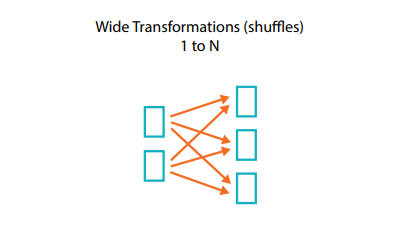
    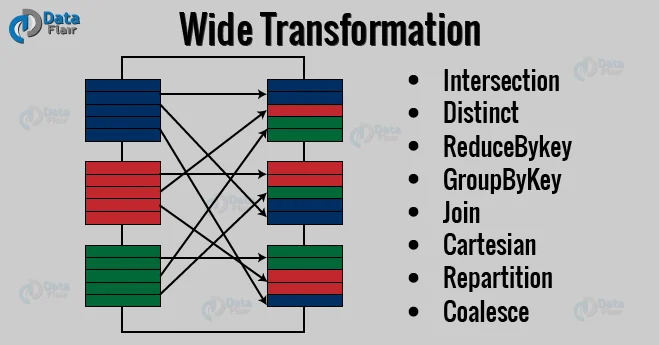

| Narrow (no shuffle) | Wide (shuffle) |
|---|---|
| `map`, `flatMap`, `filter`, `keyBy` | `groupBy`, `groupByKey`, `reduceByKey`, `join`, `distinct` |

| | Narrow | Wide |
|---|---|---|
| Output partition depends on | **One** input partition | **Many** input partitions |
| Data moves across the network? | ❌ No | ✅ Yes (shuffle) |
| Speed | Fast | Slow / expensive |
| Effect on stages | Chained into the same stage | Starts a **new stage** |
| In `.explain()` | No `Exchange` | `Exchange` appears |
| Examples | `select`, `filter`, `withColumn`, `map` | `groupBy`, `join`, `distinct`, `orderBy` |

## 11. `groupBy`
Transformation / **wide** — group elements by the result of a function. Returns pairs `(key, group of items)`.

![](http://i.imgur.com/gdj0Ey8.png)

In [ ]:
rdd = sc.parallelize(['John', 'Fred', 'Anna', 'James', 'Frank'])
rdd2 = rdd.groupBy(lambda w: w[0])
rdd2.collect()
# -> [('A', <pyspark.resultiterable.ResultIterable ...>), ('F', ...), ('J', ...)]

The group is a `ResultIterable` — convert it to a `list` to see the items:

In [ ]:
rdd2.map(lambda x: (x[0], list(x[1]))).collect()
# -> [('A', ['Anna']), ('F', ['Fred', 'Frank']), ('J', ['John', 'James'])]

In [ ]:
rdd2.map(lambda T: (T[0], len(T[1]))).collect()        # size of each group
# -> [('A', 1), ('F', 2), ('J', 2)]

In [ ]:
rdd2.map(lambda T: (T[0], sorted(T[1]))).collect()     # sorted items in each group
# -> [('A', ['Anna']), ('F', ['Frank', 'Fred']), ('J', ['James', 'John'])]

In [ ]:
print(rdd2.first())               # -> ('A', <pyspark.resultiterable.ResultIterable ...>)
print(list(rdd2.first()[1]))      # -> ['Anna']

In [ ]:
# Same result with plain Python on the driver
rdd2_lst = rdd2.collect()
[(k, list(v)) for (k, v) in rdd2_lst]
# -> [('A', ['Anna']), ('F', ['Fred', 'Frank']), ('J', ['John', 'James'])]

Group numbers into even (0) and odd (1):

In [ ]:
rdd = sc.parallelize([1, 1, 2, 3, 5, 8])
rdd_g = rdd.groupBy(lambda x: x % 2)

print(rdd_g.map(lambda x: (x[0], list(x[1]))).collect())
# -> [(0, [2, 8]), (1, [1, 1, 3, 5])]

result = rdd_g.collect()
print(sorted([(x, sorted(y)) for (x, y) in result]))
# -> [(0, [2, 8]), (1, [1, 1, 3, 5])]

Group words by first letter, then count each group:

In [ ]:
rddgroups = rddflatmap.groupBy(lambda w: w[0])
print(rddgroups.getNumPartitions())

rddgroups_list = rddgroups.map(lambda x: (x[0], list(x[1])))
print(rddgroups_list.collect())
# -> [('c', ['cat', 'cat', 'cat', 'cat']), ('d', ['dog', 'dog', 'dog']), ('o', ['owl', 'owl']), ('s', ['snake', 'snake', 'snake'])]

rdd_count = rddgroups.map(lambda x: (x[0], len(x[1])))
print(rdd_count.collect())
# -> [('c', 4), ('d', 3), ('o', 2), ('s', 3)]

Group the flight rows by destination, and by (destination, origin):

In [ ]:
G = distFile2_mapped_Comma.groupBy(lambda x: x[0])
print(G.count())    # -> 148  distinct destinations (the header 'DEST_COUNTRY_NAME' counts as one!)
GL = G.map(lambda x: (x[0], list(x[1])))
GL.take(3)

In [ ]:
G2 = distFile2_mapped_Comma.groupBy(lambda x: (x[0], x[1])) \
                           .map(lambda x: (x[0], list(x[1])))
print(G2.count())   # -> 294  distinct (dest, origin) pairs, header pair included
G2.take(3)

## 12. `groupByKey`
Transformation / **wide** — for a pair RDD, collect all values that share the same key.

![](http://i.imgur.com/TlWRGr2.png)

In [ ]:
rdd = sc.parallelize([('B', 5), ('B', 4), ('A', 3), ('A', 2), ('A', 1)])
rdd2 = rdd.groupByKey()
rdd2.map(lambda x: (x[0], list(x[1]))).collect()
# -> [('B', [5, 4]), ('A', [3, 2, 1])]

In [ ]:
print(sorted([(j[0], list(j[1])) for j in rdd2.collect()]))
# -> [('A', [3, 2, 1]), ('B', [5, 4])]
print(sorted([(j[0], sorted(list(j[1]))) for j in rdd2.collect()]))
# -> [('A', [1, 2, 3]), ('B', [4, 5])]

In [ ]:
# Sort the values inside each group, then sort by key — all on the cluster
rdd_sorted = rdd2.map(lambda T: (T[0], sorted(T[1]))).sortByKey()
rdd_sorted.collect()
# -> [('A', [1, 2, 3]), ('B', [4, 5])]

In [ ]:
rddkeys.groupByKey().map(lambda x: (x[0], list(x[1]))).collect()
# -> [('c', ['cat', 'cat', 'cat', 'cat']), ('d', [...]), ('o', [...]), ('s', [...])]

In [ ]:
# Same counts as groupBy above
print(distFile2_mapped_Comma_Keys.groupByKey().count())      # -> 148
print(distFile2_mapped_Comma_Keys_2.groupByKey().count())    # -> 294

### Example: average age per name with `groupByKey`

In [ ]:
data = [('Ahmed', 20), ('Ahmed', 60),
        ('Ayman', 15), ('Shima', 12),
        ('Sara', 13), ('Ahmed', 45),
        ('Shima', 80), ('Sara', 30)]

rdddata = sc.parallelize(data)
rdddata.cache()

rdd_bykey = rdddata.groupByKey()
rdd_bykey.map(lambda x: (x[0], list(x[1]))).collect()
# -> [('Sara', [13, 30]), ('Ahmed', [20, 60, 45]), ('Ayman', [15]), ('Shima', [12, 80])]

In [ ]:
rdd_result = rdd_bykey.map(lambda x: (x[0], sum(x[1]) / len(x[1])))
rdd_result.collect()
# -> [('Sara', 21.5), ('Ahmed', 41.666666666666664), ('Ayman', 15.0), ('Shima', 46.0)]

## 13. `reduceByKey` — average per key
Same average, but with `reduceByKey`. It combines values **inside each partition first**, so much less data is
shuffled than with `groupByKey`.

1. `map` each record to `(name, (age, 1))`
2. `reduceByKey` adds the ages and the counts → `(name, (total_age, count))`
3. `map` to `(name, total_age / count)`

In [ ]:
s1 = rdddata.map(lambda x: (x[0], (x[1], 1)))
s1.collect()
# -> [('Ahmed', (20, 1)), ('Ahmed', (60, 1)), ('Ayman', (15, 1)), ...]

In [ ]:
s2 = s1.reduceByKey(lambda x, y: (x[0] + y[0], x[1] + y[1]))
s2.collect()
# -> [('Sara', (43, 2)), ('Ahmed', (125, 3)), ('Ayman', (15, 1)), ('Shima', (92, 2))]

In [ ]:
s3 = s2.map(lambda x: (x[0], x[1][0] / x[1][1]))
s3.collect()
# -> [('Sara', 21.5), ('Ahmed', 41.666666666666664), ('Ayman', 15.0), ('Shima', 46.0)]

All three steps chained together (from L3):

In [ ]:
dataRDD = sc.parallelize([("Brooke", 20), ("Denny", 31), ("Jules", 30),
                          ("TD", 35), ("Brooke", 25), ("Jules", 40), ("Denny", 51)])

agesRDD = (dataRDD
           .map(lambda x: (x[0], (x[1], 1)))
           .reduceByKey(lambda x, y: (x[0] + y[0], x[1] + y[1]))
           .map(lambda x: (x[0], x[1][0] / x[1][1])))

agesRDD.collect()
# -> [('Jules', 35.0), ('TD', 35.0), ('Brooke', 22.5), ('Denny', 41.0)]

In [ ]:
# The groupByKey version of the same query
rdd_av = (dataRDD.groupByKey()
          .map(lambda x: (x[0], sum(x[-1]) / len(x[-1]))))
rdd_av.collect()
# -> [('Jules', 35.0), ('TD', 35.0), ('Brooke', 22.5), ('Denny', 41.0)]

## 14. `join`
Transformation / **wide** — for two pair RDDs, return every pair of values that share the same key.
Keys found in only one RDD are dropped (inner join).

![](http://i.imgur.com/YXL42Nl.png)

In [ ]:
rdd1 = sc.parallelize([("a", 1), ("b", 2), ('c', 10)])
rdd2 = sc.parallelize([("a", 3), ("a", 4), ('a', 15), ("b", 5)])

rdd1.join(rdd2).collect()
# -> [('a', (1, 3)), ('a', (1, 4)), ('a', (1, 15)), ('b', (2, 5))]     'c' is dropped

In [ ]:
rdd3 = rdd2.join(rdd1)      # order matters: values come out as (rdd2 value, rdd1 value)
rdd3.collect()
# -> [('a', (3, 1)), ('a', (4, 1)), ('a', (15, 1)), ('b', (5, 2))]

In [ ]:
rdd4 = rdd3.groupByKey()
rdd4.map(lambda x: (x[0], list(x[1]))).collect()
# -> [('a', [(3, 1), (4, 1), (15, 1)]), ('b', [(5, 2)])]

## 15. `distinct`
Transformation / **wide** — remove duplicates.

![](http://i.imgur.com/Vqgy2a4.png)

In [ ]:
rdd = sc.parallelize([1, 2, 3, 3, 4, 5, 10, 5, 5, 5, 2, 2, 2])
rdd.distinct().collect()
# -> [1, 2, 3, 4, 5, 10]

In [ ]:
txtrdd_flat = text_rdd.flatMap(lambda line: line.split())
txtrdd_flat.distinct().collect()
# -> ['first', 'line', 'then', 'fourth', 'second', 'the', 'third', 'a']

## 16. More actions

![](http://i.imgur.com/R72uzwX.png)

In [ ]:
rdd = sc.parallelize(list(range(8)))
rdd2 = rdd.map(lambda x: x**2)

rdd2.reduce(lambda a, b: a + b)    # reduce is an action!
# -> 140

In [ ]:
from operator import add
rdd2.reduce(add)
# -> 140

### `max`, `min`, `sum`, `mean`, `variance`, `stdev`
Action — compute statistics on a numeric RDD.

![](http://i.imgur.com/HUCtib1.png)

In [ ]:
print(rdd2.collect())                # -> [0, 1, 4, 9, 16, 25, 36, 49]
print('Max:      ', rdd2.max())      # -> 49
print('Min:      ', rdd2.min())      # -> 0
print('Sum:      ', rdd2.sum())      # -> 140
print('Mean:     ', rdd2.mean())     # -> 17.5
print('Variance: ', rdd2.variance()) # -> 278.25
print('Stdev:    ', rdd2.stdev())    # -> 16.680827317612277

## 17. `countByKey`
Action — return a dictionary `{key: number of occurrences}` to the driver.

![](http://i.imgur.com/jvQTGv6.png)

In [ ]:
rdd = sc.parallelize([('J', 'James'), ('F', 'Fred'),
                      ('A', 'Anna'), ('J', 'John')])

dic = rdd.countByKey()
dic
# -> defaultdict(int, {'J': 2, 'F': 1, 'A': 1})

In [ ]:
print(dic.get('J'))    # -> 2
print(dic.get('F'))    # -> 1

In [ ]:
rddkeys.countByKey()
# -> defaultdict(int, {'c': 4, 'd': 3, 's': 3, 'o': 2})

In [ ]:
dest_counts = distFile2_mapped_Comma_Keys.countByKey()        # rows per destination
print(dest_counts['United States'])    # -> 775
print(dest_counts['Egypt'])            # -> 6
# dest_counts

In [ ]:
distFile2_mapped_Comma_Keys_2.countByKey()      # rows per (destination, origin)

## 18. Working with Hadoop HDFS
### 18.1 Reading from HDFS
On the cluster, the course data lives in **HDFS** under `/user/user/data`. You can point Spark at it in several ways —
all of these read the **same** folder:

| Path | Meaning |
|---|---|
| `hdfs://bdss/user/user/data/csv` | Full URI. `bdss` is the HDFS *nameservice*: two NameNodes (master1, master2) with automatic failover |
| `hdfs:///user/user/data/csv` | Uses the cluster's default file system (`fs.defaultFS = hdfs://bdss`) |
| `data/csv` | Relative path → your HDFS home folder `/user/user` |
| `file:///home/user/notebooks/Day1/data/csv` | Forces the **local** disk — only safe in `local[*]` mode, because executors on other machines can't see this folder |

In [ ]:
HDFS_DIR = 'hdfs:///user/user/data'

# Handy access to Hadoop's FileSystem API from Python (through Spark's JVM gateway)
jvm = sc._jvm
fs = jvm.org.apache.hadoop.fs.FileSystem.get(sc._jsc.hadoopConfiguration())
Path = jvm.org.apache.hadoop.fs.Path

In [ ]:
print(sc._jsc.hadoopConfiguration().get('fs.defaultFS'))    # -> hdfs://bdss

In [ ]:
for status in fs.listStatus(Path(f'{HDFS_DIR}/csv')):
    print(status.getPath().getName(), status.getLen(), 'bytes')

You can also run any `hdfs dfs` shell command from a notebook cell with `!`:

In [ ]:
!hdfs dfs -ls -R /user/user/data

In [ ]:
flights_hdfs = sc.textFile(f'{HDFS_DIR}/csv')

print(flights_hdfs.getNumPartitions())    # -> 6 (one per file)

print(flights_hdfs.count())               # -> 1531

flights_hdfs.take(3)

In [ ]:
# Three ways to write the same HDFS path -> same result
for path in ['hdfs://bdss/user/user/data/csv', 'hdfs:///user/user/data/csv', 'data/csv']:
    print(f'{path:35}', sc.textFile(path).count())
# -> 1531 for all three

Read **one file**, or pick files with a **wildcard**:

In [ ]:
y2010 = sc.textFile(f'{HDFS_DIR}/csv/2010-summary.csv')
print(y2010.count())       # -> 253  (2010 only)

y2010_2012 = sc.textFile(f'{HDFS_DIR}/csv/201[0-2]-summary.csv')
print(y2010_2012.count())  # -> 766  (2010, 2011 and 2012)

`wholeTextFiles` returns one record per **file**: `(file path, whole file content)` — useful when each file is one document:

In [ ]:
files = sc.wholeTextFiles(f'{HDFS_DIR}/csv')

files.map( lambda kv: (kv[0].split('/')[-1], len( kv[1].splitlines() ) ) ).sortByKey().collect()

# -> [('2010-summary.csv', 253), ('2011-summary.csv', ...), ...]

### 18.2 HDFS blocks → Spark partitions
HDFS stores big files in **128 MB blocks**, and `textFile` creates about **one partition per block**.
This cell uses any big file already in HDFS (the 1 GB `/Labs/sales_data.csv`, if it exists on your cluster):

In [ ]:
big = Path('/Labs/sales_data.csv')

if fs.exists(big):
    size_mb = fs.getFileStatus(big).getLen() / 1024**2
    print(f'{size_mb:.0f} MB  /  128 MB blocks  ->  {sc.textFile(str(big)).getNumPartitions()} partitions')
else:
    print('No big file at', big, '- upload one with: hdfs dfs -put <file> /Labs/')

### 18.3 Writing an RDD back to HDFS
`saveAsTextFile` is an **action**. It writes a **folder** with one `part-0000N` file per partition, plus an empty
`_SUCCESS` marker. It fails if the folder already exists, so we delete it first.

In [ ]:
OUT_DIR = f'{HDFS_DIR}/output/egypt_flights'

if fs.exists(Path(OUT_DIR)):
    fs.delete(Path(OUT_DIR), True)        # True = recursive

In [ ]:
egypt = sc.textFile(f'{HDFS_DIR}/csv').filter(lambda line: 'Egypt' in line)
egypt.saveAsTextFile(OUT_DIR)

In [ ]:
!hdfs dfs -ls {OUT_DIR}

In [ ]:
# Read the result back from HDFS
sc.textFile(OUT_DIR).count()
# -> 12

In [ ]:
# coalesce(1) -> a single part file (fine for small results only)
OUT_ONE = f'{HDFS_DIR}/output/egypt_flights_single'

if fs.exists(Path(OUT_ONE)):
    fs.delete(Path(OUT_ONE), True)

egypt.coalesce(1).saveAsTextFile(OUT_ONE)

print([s.getPath().getName() for s in fs.listStatus(Path(OUT_ONE))])
# -> ['_SUCCESS', 'part-00000']

## 19. RDDs have no schema — the "bad data" example
An RDD doesn't know the type of its values. One wrong value (`'20'` as a string) is only discovered
**when an action runs**, and the whole job fails with a `TypeError` inside the executor.

A DataFrame would read the column with a schema instead (in class, the same data became an `age: string` column).

In [ ]:
baddata = [('Ahmed', 20), ('Ahmed', 60),
           ('Ayman', 15), ('Shima', 12),
           ('Sara', 13), ('Ahmed', 45),
           ('Shima', 80), ('Sara', 30), ('Sara', '20')]     # <- '20' is a string

baddatardd = sc.parallelize(baddata)

rdd_bykey_bad = baddatardd.groupByKey() \
                          .map(lambda x: (x[0], list(x[1]))) \
                          .map(lambda x: (x[0], sum(x[1]) / len(x[1])))   # no error yet — lazy!

try:
    rdd_bykey_bad.collect()                                  # the action triggers the failure
except Exception as e:
    print('Job failed:', type(e).__name__)
    print("Cause: TypeError: unsupported operand type(s) for +: 'int' and 'str'")

## 20. RDD vs DataFrame
The `reduceByKey` average above tells Spark **how** to compute the result with a chain of lambdas.
It's hard to read, and Spark can't see the intention, so it can't optimize it.

The DataFrame API says **what** you want, and Spark plans the best way to do it.

In [ ]:
from pyspark.sql.functions import avg

data_df = spark.createDataFrame([("Brooke", 20), ("Denny", 31), ("Jules", 30),
                                 ("TD", 35), ("Brooke", 25), ("Jules", 40), ("Denny", 51)],
                                ['name', 'age'])

data_df.groupBy('name').agg(avg('age').alias('avg_age')).show()

Every DataFrame is built on an RDD — you can reach it with `.rdd`:

In [ ]:
print(data_df.rdd.getNumPartitions())
data_df.rdd.collect()
# -> [Row(name='Brooke', age=20), Row(name='Denny', age=31), ...]

## 21. Stages & stopping Spark
- A **stage** is a physical unit of execution: a group of tasks. The DAG of your transformations decides the stages.
- Every **wide** transformation (shuffle) starts a new stage.
- **ShuffleMapStage**: an intermediate stage that prepares data for the next stage.
- **ResultStage**: the final stage that computes the action's result.

Open the Spark UI (usually http://localhost:4040) while running the examples to see jobs, stages and tasks.

In [ ]:
# Stop the local Spark cluster
sc.stop()

## 22. 📋 Cheat sheet — summary of everything

### The big idea
| Rule | Meaning |
|---|---|
| **RDD** | Resilient Distributed Dataset — an immutable list of items split into **partitions** across the cluster |
| **Transformation** | Builds a **new RDD**. **Lazy** — nothing runs yet, Spark only records the step |
| **Action** | Returns a result to the driver (or writes to storage). **Triggers** the whole chain to run |
| **Narrow** | Each output partition needs **one** input partition → no shuffle, same stage |
| **Wide** | Output partitions need data from **many** input partitions → **shuffle**, new stage |
| Job → Stage → Task | One action = one **job**; every shuffle splits it into **stages**; each stage = many **tasks** (one per partition) |

### Starting & stopping Spark
| Code | What it does |
|---|---|
| `SparkSession.builder.appName('RDD').getOrCreate()` | Create (or reuse) a session — the modern entry point |
| `.master('local[*]')` | Run on this machine, one thread per CPU core (default on the cluster is `yarn`) |
| `sc = spark.sparkContext` | Get the SparkContext used for RDDs |
| `SparkContext(conf=SparkConf()...)` | Old Spark 1.x way — only **one** SparkContext per JVM |
| `sc.stop()` | Stop Spark and free the resources |

### Creating RDDs
| Code | Result |
|---|---|
| `sc.parallelize([1, 2, 3])` | RDD from a Python list in the driver |
| `sc.textFile('file.txt')` | RDD of **lines** from one file |
| `sc.textFile('folder')` | Lines of **every** file in the folder |
| `sc.textFile('folder/201[0-2]-*.csv')` | Wildcards pick some files |
| `sc.textFile(path, minPartitions=8)` | Ask for at least 8 partitions |
| `sc.wholeTextFiles('folder')` | One record per **file**: `(path, whole content)` |
| `rdd.getNumPartitions()` | How many partitions the RDD has |

### Narrow transformations (no shuffle)
| Code | Result | Example |
|---|---|---|
| `map(f)` | One input → exactly **one** output | `[1, 2, 3]` → `map(lambda x: x*2)` → `[2, 4, 6]` |
| `flatMap(f)` | One input → 0, 1 or **many** outputs, then **flatten** | `['a b', 'c']` → `flatMap(lambda x: x.split())` → `['a', 'b', 'c']` |
| `filter(f)` | Keep elements where `f` returns `True` | `filter(lambda x: x % 2 == 0)` → even numbers only |
| `keyBy(f)` | Make pairs `(f(x), x)` → a **pair RDD** | `['John', 'Anna']` → `keyBy(lambda w: w[0])` → `[('J','John'), ('A','Anna')]` |
| `sample(True, 0.25)` | Random sample of ~25% of the elements | |
| `union(other)` | Append another RDD | |
| `coalesce(n)` | Reduce the number of partitions (e.g. `coalesce(1)` before saving) | |

### Wide transformations (shuffle)
| Code | Result | Example |
|---|---|---|
| `groupBy(f)` | `(key, group of items)` — key is `f(x)` | `groupBy(lambda w: w[0])` → `('J', ['John', 'James'])` |
| `groupByKey()` | For pair RDDs: `(key, all values)` | `[('A',3), ('A',2)]` → `('A', [3, 2])` |
| `reduceByKey(f)` | For pair RDDs: combine the values of each key with `f` | `reduceByKey(lambda a, b: a + b)` → total per key |
| `join(other)` | Inner join on the key → `(key, (v1, v2))` | keys found in only one RDD are dropped |
| `distinct()` | Remove duplicates | `[1, 2, 2, 3]` → `[1, 2, 3]` |
| `sortByKey()` / `sortBy(f, ascending=False)` | Sort by key / by any value | |

> 💡 A group from `groupBy` / `groupByKey` is a `ResultIterable` — wrap it in `list(...)` to see the items.

### Actions (run the job, return a result)
| Code | Result |
|---|---|
| `collect()` | **Whole** RDD as a Python list — only for small results! |
| `take(n)` / `first()` | First `n` elements / the first element |
| `top(n)` | Largest `n` elements |
| `takeSample(True, 3)` | Random sample of 3 elements |
| `count()` | Number of elements |
| `reduce(f)` | Combine all elements, e.g. `reduce(lambda a, b: a + b)` or `reduce(add)` |
| `sum()` `max()` `min()` `mean()` `variance()` `stdev()` | Numeric statistics |
| `countByKey()` | For pair RDDs: `{key: number of rows}` as a Python dict |
| `saveAsTextFile(path)` | Write a **folder** of `part-0000N` files (one per partition) + `_SUCCESS` |

### Caching / persisting
| Code | What it does |
|---|---|
| `rdd.cache()` | Keep in memory (`MEMORY_ONLY`) after the **first action** — `cache()` itself is lazy |
| `rdd.persist(StorageLevel.MEMORY_AND_DISK)` | Memory first, the rest goes to disk |
| `rdd.persist(StorageLevel.DISK_ONLY)` | Disk only |
| `rdd.getStorageLevel()` | Show the current storage level |
| `rdd.unpersist()` | Remove from the cache |

### Working with HDFS
| Path / command | Meaning |
|---|---|
| `hdfs://bdss/user/user/data/csv` | Full URI (`bdss` = HA nameservice with two NameNodes) |
| `hdfs:///user/user/data/csv` | Uses the default file system (`fs.defaultFS`) |
| `data/csv` | Relative → your HDFS home folder `/user/user` |
| `file:///...` | Forces the **local** disk — only safe in `local[*]` mode |
| `!hdfs dfs -ls -R /user/user/data` | Run an HDFS shell command from a notebook cell |
| `fs.exists(Path(p))` / `fs.delete(Path(p), True)` | Check / delete a folder before `saveAsTextFile` |
| 128 MB blocks | `textFile` makes about **one partition per HDFS block** |

### Common patterns
```python
# Split CSV lines into columns and drop the header
rows = sc.textFile('data/csv').filter(lambda x: 'DEST_COUNTRY_NAME' not in x).map(lambda x: x.split(','))

# Count words starting with each letter
words = sc.textFile('data/text/text.txt').flatMap(lambda x: x.split())
words.keyBy(lambda w: w[0]).countByKey()

# Average per key with reduceByKey (fast: combines inside each partition before the shuffle)
(pairs.map(lambda x: (x[0], (x[1], 1)))
      .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
      .map(lambda x: (x[0], x[1][0] / x[1][1])))
```

### ⚠️ Common mistakes to remember
| Mistake | Remember |
|---|---|
| Calling `collect()` on big data | It brings **everything** to the driver → use `take(n)` |
| Using `split()` on CSV lines | Splits on spaces — use `split(',')` |
| Forgetting the CSV header | `textFile` reads the header as a normal line (6 files → 6 headers) |
| `groupByKey` for sums / averages | Prefer `reduceByKey` — much less data is shuffled |
| `saveAsTextFile` to an existing folder | It fails — delete the folder first |
| `sc.textFile` on Parquet | Gives binary garbage — use `spark.read.parquet(...)` |
| Creating a second `SparkContext` | Only one per JVM — use `getOrCreate()` |
| Expecting an error at the transformation | RDDs have **no schema**; bad data fails only when the **action** runs |
| Writing complex lambda chains | The DataFrame API says **what** you want, so Spark can optimize it |